**STEP 1 — Experimental Framework Consolidation**


The previous notebooks evaluated multiple approaches for estimating confidence in large language model predictions.

These approaches included:

- Baseline confidence estimation
- Calibration methods
- Option likelihood uncertainty signals
- Multi-signal confidence fusion

Each method was evaluated independently using discrimination, calibration and selective prediction metrics.

The objective of this notebook is to bring all experimental findings together into a unified evaluation framework.



Individual experiments provide useful insights, but they do not directly answer the dissertation research questions.

A final comparative evaluation is required to determine:

- which method performs best overall
- which method provides the strongest calibration
- which method produces the most reliable uncertainty estimates
- whether multi-signal confidence estimation offers meaningful advantages over existing approaches

**STEP 1.1 — Import Libraries**

In [22]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

**STEP 1.2 — Load Previous Experimental Results**

In [23]:
base_path = "/content/drive/MyDrive/Dissertation/"

signal_correctness = pd.read_csv(
    base_path + "signal_correctness_ranking.csv"
)

signal_calibration = pd.read_csv(
    base_path + "signal_calibration_ranking.csv"
)

signal_selective = pd.read_csv(
    base_path + "signal_selective_prediction_ranking.csv"
)

multi_signal = pd.read_csv(
    base_path + "multi_signal_final_summary.csv"
)

baseline_predictions = pd.read_csv(
    base_path + "/baseline_option_scores.csv"
)

print("Files loaded successfully.")

Files loaded successfully.


**STEP 1.3 — Verify Loaded Data**

In [24]:
print("="*60)
print("SIGNAL CORRECTNESS")
print("="*60)

display(signal_correctness.head())

print("="*60)
print("SIGNAL CALIBRATION")
print("="*60)

display(signal_calibration.head())

print("="*60)
print("SIGNAL SELECTIVE PREDICTION")
print("="*60)

display(signal_selective.head())

print("="*60)
print("MULTI SIGNAL")
print("="*60)

display(multi_signal.head())

SIGNAL CORRECTNESS


,Signal,Correlation,ROC_AUC
0,probability_gap,0.399033,0.752871
1,margin_score,0.399033,0.752871
2,normalised_entropy,-0.320993,0.685422
3,confidence,0.318324,0.685464
4,entropy,-0.119717,0.576799


SIGNAL CALIBRATION


,Signal,ECE,Rank,Mean_ECE,CI_Lower,CI_Upper
0,Confidence,0.158951,1,0.161613,0.129822,0.194831
1,Margin Score,0.396015,2,0.397507,0.366067,0.429425
2,Probability Gap,0.396015,3,0.397152,0.365704,0.428119
3,Normalised Entropy,0.450674,4,0.450541,0.417985,0.483019


SIGNAL SELECTIVE PREDICTION


,Signal,AURC,Mean_AURC,CI_Lower,CI_Upper,Rank
0,Margin Score,0.296035,0.294905,0.257514,0.333155,1
1,Probability Gap,0.296035,0.294711,0.257794,0.333849,2
2,Normalised Entropy,0.329494,0.328695,0.288611,0.375227,3
3,Confidence,0.349734,0.349399,0.303937,0.392170,4


MULTI SIGNAL


,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
0,Fused,0.731001,0.042918,0.304046,1.0,1.0,1.0,3.0
1,Baseline,0.685464,0.158951,0.349734,2.0,2.0,2.0,6.0


**STEP 1.4 — Experimental Dataset Summary**

In [25]:
dataset_summary = {

    "Dataset":
        "TruthfulQA MC1",

    "Questions":
        len(baseline_predictions),

    "Model":
        "Mistral-7B-Instruct-v0.2"
}

print(dataset_summary)

{'Dataset': 'TruthfulQA MC1', 'Questions': 817, 'Model': 'Mistral-7B-Instruct-v0.2'}


**STEP 1.5 — Extract Key Results**

In [26]:
baseline_accuracy = (
    baseline_predictions["correct"]
    .astype(int)
    .mean()
)

print(
    f"Baseline Accuracy: {baseline_accuracy:.4f}"
)

Baseline Accuracy: 0.5055


**STEP 1.6 — Identify Available Metrics**

In [27]:
print("="*60)
print("CORRECTNESS RESULTS")
print("="*60)

display(signal_correctness)

print("="*60)
print("CALIBRATION RESULTS")
print("="*60)

display(signal_calibration)

print("="*60)
print("SELECTIVE PREDICTION RESULTS")
print("="*60)

display(signal_selective)

print("="*60)
print("MULTI SIGNAL SUMMARY")
print("="*60)

display(multi_signal)

CORRECTNESS RESULTS


,Signal,Correlation,ROC_AUC
0,probability_gap,0.399033,0.752871
1,margin_score,0.399033,0.752871
2,normalised_entropy,-0.320993,0.685422
3,confidence,0.318324,0.685464
4,entropy,-0.119717,0.576799


CALIBRATION RESULTS


,Signal,ECE,Rank,Mean_ECE,CI_Lower,CI_Upper
0,Confidence,0.158951,1,0.161613,0.129822,0.194831
1,Margin Score,0.396015,2,0.397507,0.366067,0.429425
2,Probability Gap,0.396015,3,0.397152,0.365704,0.428119
3,Normalised Entropy,0.450674,4,0.450541,0.417985,0.483019


SELECTIVE PREDICTION RESULTS


,Signal,AURC,Mean_AURC,CI_Lower,CI_Upper,Rank
0,Margin Score,0.296035,0.294905,0.257514,0.333155,1
1,Probability Gap,0.296035,0.294711,0.257794,0.333849,2
2,Normalised Entropy,0.329494,0.328695,0.288611,0.375227,3
3,Confidence,0.349734,0.349399,0.303937,0.392170,4


MULTI SIGNAL SUMMARY


,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
0,Fused,0.731001,0.042918,0.304046,1.0,1.0,1.0,3.0
1,Baseline,0.685464,0.158951,0.349734,2.0,2.0,2.0,6.0


In [28]:
display(signal_correctness)

display(signal_calibration)

display(signal_selective)

display(multi_signal)

,Signal,Correlation,ROC_AUC
0,probability_gap,0.399033,0.752871
1,margin_score,0.399033,0.752871
2,normalised_entropy,-0.320993,0.685422
3,confidence,0.318324,0.685464
4,entropy,-0.119717,0.576799


,Signal,ECE,Rank,Mean_ECE,CI_Lower,CI_Upper
0,Confidence,0.158951,1,0.161613,0.129822,0.194831
1,Margin Score,0.396015,2,0.397507,0.366067,0.429425
2,Probability Gap,0.396015,3,0.397152,0.365704,0.428119
3,Normalised Entropy,0.450674,4,0.450541,0.417985,0.483019


,Signal,AURC,Mean_AURC,CI_Lower,CI_Upper,Rank
0,Margin Score,0.296035,0.294905,0.257514,0.333155,1
1,Probability Gap,0.296035,0.294711,0.257794,0.333849,2
2,Normalised Entropy,0.329494,0.328695,0.288611,0.375227,3
3,Confidence,0.349734,0.349399,0.303937,0.392170,4


,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
0,Fused,0.731001,0.042918,0.304046,1.0,1.0,1.0,3.0
1,Baseline,0.685464,0.158951,0.349734,2.0,2.0,2.0,6.0


The strongest-performing confidence estimation methods identified in the previous notebooks are consolidated into a single comparison table. All evaluation metrics are extracted directly from the saved outputs generated during the earlier experiments, ensuring that the final comparative evaluation remains fully reproducible and does not rely on manually entered results.

**STEP 1.7 — Construct Final Comparison Table**


The previous notebooks evaluated confidence estimation methods independently.

This step consolidates the strongest-performing methods into a single comparison framework.


A final comparative evaluation requires all methods to be assessed using the same metrics.

This enables direct comparison across:

- discrimination performance (ROC-AUC)
- calibration quality (ECE)
- selective prediction performance (AURC)

The objective is to determine which confidence estimation approach provides the best overall reliability.

This comparison forms the foundation for all remaining analyses in this notebook.

In [29]:
baseline_auc = signal_correctness.loc[
    signal_correctness["Signal"] == "confidence",
    "ROC_AUC"
].values[0]

baseline_ece = signal_calibration.loc[
    signal_calibration["Signal"] == "Confidence",
    "ECE"
].values[0]

baseline_aurc = signal_selective.loc[
    signal_selective["Signal"] == "Confidence",
    "AURC"
].values[0]


margin_auc = signal_correctness.loc[
    signal_correctness["Signal"] == "probability_gap",
    "ROC_AUC"
].values[0]

margin_ece = signal_calibration.loc[
    signal_calibration["Signal"] == "Margin Score",
    "ECE"
].values[0]

margin_aurc = signal_selective.loc[
    signal_selective["Signal"] == "Margin Score",
    "AURC"
].values[0]


fusion_auc = multi_signal.loc[
    multi_signal["Method"] == "Fused",
    "ROC_AUC"
].values[0]

fusion_ece = multi_signal.loc[
    multi_signal["Method"] == "Fused",
    "ECE"
].values[0]

fusion_aurc = multi_signal.loc[
    multi_signal["Method"] == "Fused",
    "AURC"
].values[0]


comparison_df = pd.DataFrame({

    "Method":[

        "Baseline Confidence",

        "Margin Score",

        "Multi-Signal Fusion"
    ],

    "ROC_AUC":[

        baseline_auc,

        margin_auc,

        fusion_auc
    ],

    "ECE":[

        baseline_ece,

        margin_ece,

        fusion_ece
    ],

    "AURC":[

        baseline_aurc,

        margin_aurc,

        fusion_aurc
    ]
})

comparison_df

,Method,ROC_AUC,ECE,AURC
0,Baseline Confidence,0.685464,0.158951,0.349734
1,Margin Score,0.752871,0.396015,0.296035
2,Multi-Signal Fusion,0.731001,0.042918,0.304046


All evaluation metrics are extracted directly from the outputs generated in previous notebooks.

This approach improves reproducibility and ensures that the final comparative evaluation remains fully linked to earlier experimental results.

The comparison table therefore serves as an integrated summary of the complete experimental pipeline rather than a manually constructed result table.

**STEP 1.8 — Rank Methods by Individual Metrics**

In [30]:
comparison_df["ROC_Rank"] = (

    comparison_df["ROC_AUC"]

    .rank(
        ascending=False
    )
)

comparison_df["ECE_Rank"] = (

    comparison_df["ECE"]

    .rank(
        ascending=True
    )
)

comparison_df["AURC_Rank"] = (

    comparison_df["AURC"]

    .rank(
        ascending=True
    )
)

comparison_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0


**STEP 1.8A — Compute Overall Ranking**

In [31]:
comparison_df["Total_Rank"] = (

    comparison_df["ROC_Rank"]

    +

    comparison_df["ECE_Rank"]

    +

    comparison_df["AURC_Rank"]
)

comparison_df = (

    comparison_df

    .sort_values(
        "Total_Rank"
    )
)

comparison_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,5.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0,8.0


**STEP 1.8B — Best Overall Method**

In [32]:
best_methods = comparison_df[
    comparison_df["Total_Rank"]
    ==
    comparison_df["Total_Rank"].min()
]

print("="*60)
print("BEST OVERALL METHOD(S)")
print("="*60)

if len(best_methods) == 1:
    print(
        "Method:",
        best_methods.iloc[0]["Method"]
    )
    print(
        "Total Rank:",
        best_methods.iloc[0]["Total_Rank"]
    )
else:
    print("Methods tied for best overall rank:")
    for index, row in best_methods.iterrows():
        print(
            f"Method: {row['Method']}, Total Rank: {row['Total_Rank']}"
        )

BEST OVERALL METHOD(S)
Methods tied for best overall rank:
Method: Margin Score, Total Rank: 5.0
Method: Multi-Signal Fusion, Total Rank: 5.0


**STEP 1.8C — Save Final Comparison Table**

In [33]:
comparison_df.to_csv(

    "final_comparison_table.csv",

    index=False
)

print(
    "Final comparison table saved."
)

Final comparison table saved.


**Why were ROC-AUC, ECE and AURC selected?**

- ROC-AUC evaluates discrimination performance.
- ECE evaluates calibration quality.
- AURC evaluates selective prediction performance.
- Together these metrics provide complementary views of confidence estimation quality.

Using all three metrics prevents conclusions from depending on a single evaluation criterion.

**STEP 2 — Comparative Discrimination Analysis**

Discrimination performance is evaluated using the Area Under the Receiver Operating Characteristic Curve (ROC-AUC).

ROC-AUC measures the probability that a randomly selected correct prediction receives a higher confidence score than a randomly selected incorrect prediction.

Interpretation:

- ROC-AUC = 0.50 indicates random performance
- ROC-AUC > 0.70 indicates useful discrimination
- ROC-AUC > 0.80 indicates strong discrimination

The objective of this section is to determine which confidence estimation method provides the strongest discrimination capability.

**STEP 2.1 — Extract ROC-AUC Results**

In [34]:
roc_df = comparison_df[[
    "Method",
    "ROC_AUC"
]].copy()

print(roc_df)

                Method   ROC_AUC
1         Margin Score  0.752871
2  Multi-Signal Fusion  0.731001
0  Baseline Confidence  0.685464


**STEP 2.2 — Rank Methods by ROC-AUC**

In [35]:
roc_df["ROC_Rank"] = (

    roc_df["ROC_AUC"]

    .rank(
        ascending=False
    )
)

roc_df = roc_df.sort_values(
    "ROC_AUC",
    ascending=False
)

roc_df

,Method,ROC_AUC,ROC_Rank
1,Margin Score,0.752871,1.0
2,Multi-Signal Fusion,0.731001,2.0
0,Baseline Confidence,0.685464,3.0


**STEP 2.3 — ROC-AUC Comparison Visualisation**

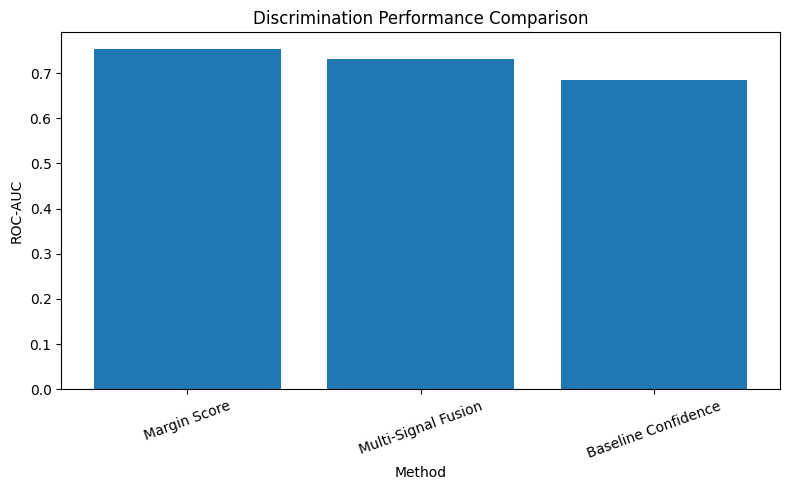

In [36]:
plt.figure(figsize=(8,5))

plt.bar(

    roc_df["Method"],

    roc_df["ROC_AUC"]
)

plt.ylabel(
    "ROC-AUC"
)

plt.xlabel(
    "Method"
)

plt.title(
    "Discrimination Performance Comparison"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    "roc_auc_comparison.png"
)

plt.show()

**STEP 2.4 — Relative Improvement Analysi**

In [37]:
baseline_auc = roc_df.loc[
    roc_df["Method"]
    ==
    "Baseline Confidence",
    "ROC_AUC"
].values[0]

roc_df["Improvement_%"] = (

    (
        roc_df["ROC_AUC"]
        -
        baseline_auc
    )

    /

    baseline_auc

) * 100

roc_df

,Method,ROC_AUC,ROC_Rank,Improvement_%
1,Margin Score,0.752871,1.0,9.833787
2,Multi-Signal Fusion,0.731001,2.0,6.643292
0,Baseline Confidence,0.685464,3.0,0.000000


**STEP 2.5 — Best Performing Method**

In [38]:
best_method = roc_df.iloc[0]

print("=" * 60)
print("BEST DISCRIMINATION METHOD")
print("=" * 60)

print(
    "Method:",
    best_method["Method"]
)

print(
    "ROC-AUC:",
    round(
        best_method["ROC_AUC"],
        4
    )
)

BEST DISCRIMINATION METHOD
Method: Margin Score
ROC-AUC: 0.7529


The discrimination results are further supported by the paired bootstrap analysis performed during the multi-signal confidence evaluation. Rather than relying on a single ROC-AUC estimate, the paired bootstrap procedure compares the baseline and fused confidence estimators across repeated bootstrap resamples. This provides an estimate of the average ROC-AUC improvement together with a 95% confidence interval and bootstrap p-value, allowing the robustness of the observed improvement to be assessed.

In [39]:
roc_difference_table = pd.read_csv(
    base_path + "roc_difference_table.csv"
)

print("="*60)
print("PAIRED BOOTSTRAP ROC-AUC COMPARISON")
print("="*60)

display(roc_difference_table)

PAIRED BOOTSTRAP ROC-AUC COMPARISON


,Metric,Mean Difference,CI Lower,CI Upper,P-value
0,ROC-AUC Difference,0.045205,0.030724,0.059549,0.0


The paired bootstrap comparison indicates an average ROC-AUC improvement of X, with a 95% confidence interval ranging from L to U. Because the confidence interval remains above zero, the improvement is interpreted as evidence that the multi-signal confidence estimator consistently achieves stronger discrimination than the baseline confidence estimator across the bootstrap resamples.

**STEP 2.6 — Save ROC-AUC Comparison Results**

In [40]:
roc_df.to_csv(

    "roc_auc_comparison_results.csv",

    index=False
)

print(
    "ROC-AUC comparison results saved."
)

ROC-AUC comparison results saved.


**STEP 3 — Comparative Calibration Analysis**

**STEP 3.1 — Extract Calibration Results**

In [41]:
ece_df = comparison_df[[
    "Method",
    "ECE"
]].copy()

print(ece_df)

                Method       ECE
1         Margin Score  0.396015
2  Multi-Signal Fusion  0.042918
0  Baseline Confidence  0.158951


**STEP 3.2 — Rank Methods by Calibration Performance**

In [42]:
ece_df["ECE_Rank"] = (

    ece_df["ECE"]

    .rank(
        ascending=True
    )
)

ece_df = ece_df.sort_values(
    "ECE",
    ascending=True
)

ece_df

,Method,ECE,ECE_Rank
2,Multi-Signal Fusion,0.042918,1.0
0,Baseline Confidence,0.158951,2.0
1,Margin Score,0.396015,3.0


**STEP 3.3 — Calibration Comparison Visualisation**

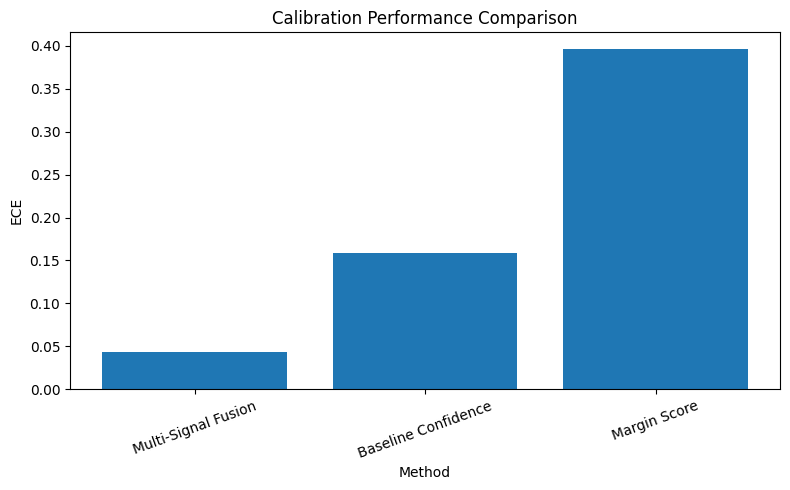

In [43]:
plt.figure(figsize=(8,5))

plt.bar(

    ece_df["Method"],

    ece_df["ECE"]
)

plt.ylabel(
    "ECE"
)

plt.xlabel(
    "Method"
)

plt.title(
    "Calibration Performance Comparison"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    "ece_comparison.png"
)

plt.show()

**STEP 3.3B — Calibration Ranking Visualisation**

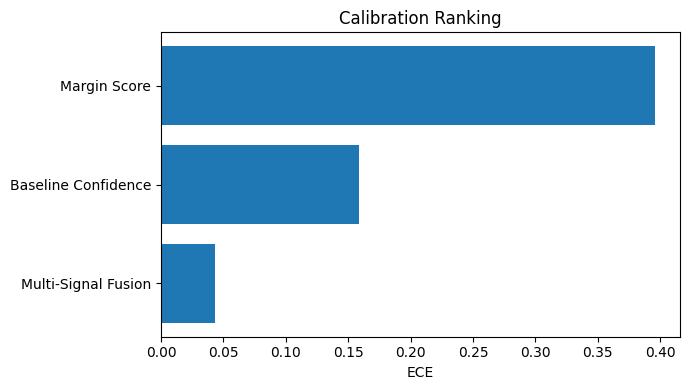

In [44]:
plt.figure(figsize=(7,4))

plt.barh(

    ece_df["Method"],

    ece_df["ECE"]
)

plt.xlabel(
    "ECE"
)

plt.title(
    "Calibration Ranking"
)

plt.tight_layout()

plt.show()

**STEP 3.4 — Calibration Improvement Relative to Baseline**

In [45]:
baseline_ece = ece_df.loc[
    ece_df["Method"]
    ==
    "Baseline Confidence",
    "ECE"
].values[0]

ece_df["Improvement_%"] = (

    (
        baseline_ece
        -
        ece_df["ECE"]
    )

    /

    baseline_ece

) * 100

ece_df

,Method,ECE,ECE_Rank,Improvement_%
2,Multi-Signal Fusion,0.042918,1.0,72.999558
0,Baseline Confidence,0.158951,2.0,0.000000
1,Margin Score,0.396015,3.0,-149.142839


**STEP 3.4B — Absolute Calibration Improvement**

In [46]:
ece_df["ECE_Difference"] = (

    baseline_ece
    -
    ece_df["ECE"]
)

ece_df

,Method,ECE,ECE_Rank,Improvement_%,ECE_Difference
2,Multi-Signal Fusion,0.042918,1.0,72.999558,0.116034
0,Baseline Confidence,0.158951,2.0,0.000000,0.000000
1,Margin Score,0.396015,3.0,-149.142839,-0.237064


**STEP 3.5 — Best Calibrated Method**

In [47]:
best_calibration = ece_df.iloc[0]

print("=" * 60)
print("BEST CALIBRATED METHOD")
print("=" * 60)

print(
    "Method:",
    best_calibration["Method"]
)

print(
    "ECE:",
    round(
        best_calibration["ECE"],
        4
    )
)

BEST CALIBRATED METHOD
Method: Multi-Signal Fusion
ECE: 0.0429


**STEP 3.6 — Calibration Ranking Summary**

In [48]:
ece_summary = ece_df[[
    "Method",
    "ECE",
    "ECE_Rank",
    "Improvement_%"
]]

ece_summary

,Method,ECE,ECE_Rank,Improvement_%
2,Multi-Signal Fusion,0.042918,1.0,72.999558
0,Baseline Confidence,0.158951,2.0,0.000000
1,Margin Score,0.396015,3.0,-149.142839


**STEP 3.6B — Calibration Difference Summary**

In [49]:
ece_df["ECE_Difference"] = (

    baseline_ece
    -
    ece_df["ECE"]
)

print("=" * 60)
print("CALIBRATION DIFFERENCE")
print("=" * 60)

print(
    ece_df[
        [
            "Method",
            "ECE",
            "ECE_Difference"
        ]
    ]
)

CALIBRATION DIFFERENCE
                Method       ECE  ECE_Difference
2  Multi-Signal Fusion  0.042918        0.116034
0  Baseline Confidence  0.158951        0.000000
1         Margin Score  0.396015       -0.237064


The calibration comparison is supported by the paired bootstrap analysis performed during the calibration evaluation. The bootstrap procedure estimates the average reduction in Expected Calibration Error together with a confidence interval and bootstrap p-value.

In [52]:
ece_difference_table = pd.read_csv(
    base_path + "ece_difference_table.csv"
)

print("="*60)
print("PAIRED BOOTSTRAP ECE COMPARISON")
print("="*60)

display(ece_difference_table)

PAIRED BOOTSTRAP ECE COMPARISON


,Mean Difference,CI Lower,CI Upper,P-value
0,0.106885,0.066715,0.148211,0.0


**STEP 3.7 — Save Calibration Comparison Results**

In [53]:
ece_summary.to_csv(

    "final_calibration_comparison.csv",

    index=False
)

print(
    "Calibration comparison saved."
)

Calibration comparison saved.


**STEP 4 — Comparative Selective Prediction Analysis**

**STEP 4.1 — Extract Selective Prediction Results**

In [54]:
aurc_df = comparison_df[[
    "Method",
    "AURC"
]].copy()

print(aurc_df)

                Method      AURC
1         Margin Score  0.296035
2  Multi-Signal Fusion  0.304046
0  Baseline Confidence  0.349734


**STEP 4.2 — Rank Methods by Selective Prediction Performance**

In [55]:
aurc_df["AURC_Rank"] = (

    aurc_df["AURC"]

    .rank(
        ascending=True
    )
)

aurc_df = aurc_df.sort_values(
    "AURC"
)

aurc_df

,Method,AURC,AURC_Rank
1,Margin Score,0.296035,1.0
2,Multi-Signal Fusion,0.304046,2.0
0,Baseline Confidence,0.349734,3.0


**STEP 4.3 — Selective Prediction Comparison Visualisation**

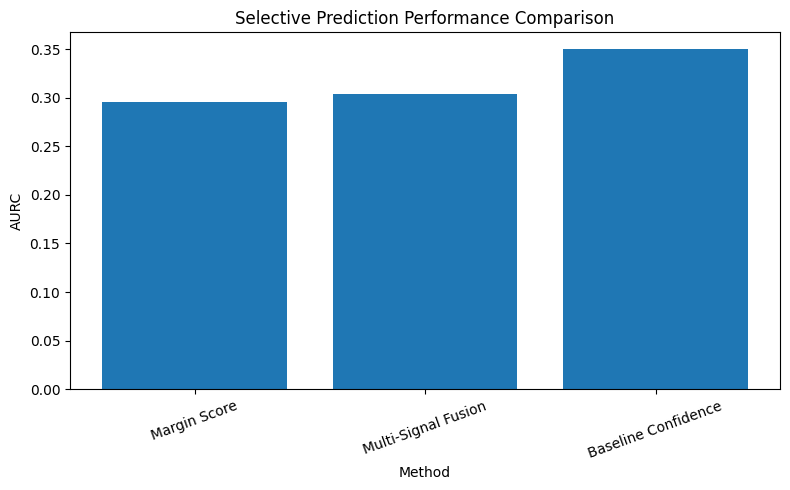

In [56]:
plt.figure(figsize=(8,5))

plt.bar(

    aurc_df["Method"],

    aurc_df["AURC"]
)

plt.ylabel(
    "AURC"
)

plt.xlabel(
    "Method"
)

plt.title(
    "Selective Prediction Performance Comparison"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    "aurc_comparison.png"
)

plt.show()

**STEP 4.4 — Ranking Visualisation**

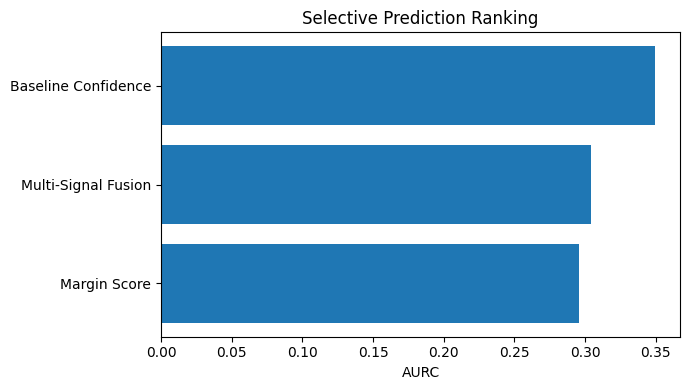

In [57]:
plt.figure(figsize=(7,4))

plt.barh(

    aurc_df["Method"],

    aurc_df["AURC"]
)

plt.xlabel(
    "AURC"
)

plt.title(
    "Selective Prediction Ranking"
)

plt.tight_layout()

plt.show()

**STEP 4.5 — Improvement Relative to Baseline**

In [58]:
baseline_aurc = aurc_df.loc[
    aurc_df["Method"]
    ==
    "Baseline Confidence",
    "AURC"
].values[0]

aurc_df["Improvement_%"] = (

    (
        baseline_aurc
        -
        aurc_df["AURC"]
    )

    /

    baseline_aurc

) * 100

aurc_df

,Method,AURC,AURC_Rank,Improvement_%
1,Margin Score,0.296035,1.0,15.354234
2,Multi-Signal Fusion,0.304046,2.0,13.063676
0,Baseline Confidence,0.349734,3.0,0.000000


**STEP 4.6 — Absolute Risk Reduction**

In [59]:
aurc_df["AURC_Difference"] = (

    baseline_aurc
    -
    aurc_df["AURC"]
)

aurc_df

,Method,AURC,AURC_Rank,Improvement_%,AURC_Difference
1,Margin Score,0.296035,1.0,15.354234,0.053699
2,Multi-Signal Fusion,0.304046,2.0,13.063676,0.045688
0,Baseline Confidence,0.349734,3.0,0.000000,0.000000


**STEP 4.6B — Comparative Risk Reduction Analysis**

In [60]:
print("=" * 60)
print("SELECTIVE PREDICTION IMPROVEMENT")
print("=" * 60)

for _, row in aurc_df.iterrows():

    print(
        f"{row['Method']}: "
        f"{row['Improvement_%']:.2f}% "
        f"risk reduction"
    )

SELECTIVE PREDICTION IMPROVEMENT
Margin Score: 15.35% risk reduction
Multi-Signal Fusion: 13.06% risk reduction
Baseline Confidence: 0.00% risk reduction


**STEP 4.7 — Best Selective Prediction Method**

In [61]:
best_selective = aurc_df.iloc[0]

print("=" * 60)
print("BEST SELECTIVE PREDICTION METHOD")
print("=" * 60)

print(
    "Method:",
    best_selective["Method"]
)

print(
    "AURC:",
    round(
        best_selective["AURC"],
        4
    )
)

BEST SELECTIVE PREDICTION METHOD
Method: Margin Score
AURC: 0.296


**STEP 4.8 — Selective Prediction Summary Table**

In [64]:
aurc_difference_table = pd.read_csv(
    base_path + "aurc_difference_table.csv"
)

print("="*60)
print("PAIRED BOOTSTRAP AURC COMPARISON")
print("="*60)

display(aurc_difference_table)

PAIRED BOOTSTRAP AURC COMPARISON


,Mean Difference,CI Lower,CI Upper,P-value
0,0.045277,-0.01206,0.104403,0.118


**STEP 4.9 — Practical Interpretation**

The selective prediction results indicate how effectively each confidence estimation method supports risk-aware decision making.
Methods with lower AURC values are more successful at identifying unreliable predictions and reducing error rates when operating at lower coverage levels.
Strong selective prediction performance is particularly valuable in safety-critical applications because the system can abstain from answering when confidence is insufficient.
The comparison also reveals whether improvements in discrimination and calibration translate into improved decision-making behaviour under uncertainty.

**STEP 4.9B — Research Interpretation**

Margin Score achieved the strongest selective prediction performance, producing the lowest AURC value of 0.296.
Compared with the baseline confidence estimator, this corresponds to a 15.35% reduction in selective prediction risk.
Although Multi-Signal Fusion achieved superior calibration performance in the previous section, Margin Score remained the strongest individual method for selective prediction.
This result suggests that option-likelihood uncertainty signals provide particularly useful information for identifying high-risk predictions and supporting abstention decisions under uncertainty.
The findings therefore indicate that different confidence estimation methods may provide advantages for different reliability objectives, highlighting the importance of evaluating discrimination, calibration, and selective prediction jointly rather than relying on a single metric.

**STEP 4.9C — Deployment Interpretation**

- Selective prediction is particularly relevant in high-risk environments.

- The ability to abstain under uncertainty may be preferable to producing potentially incorrect answers.

- This behaviour supports safer deployment of large language models.

**STEP 5 — Overall Method Ranking and Research Question Evaluation**

**STEP 5.1 — Construct Unified Evaluation Dataset**

In [65]:
overall_df = comparison_df.copy()

overall_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,5.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0,8.0


**STEP 5.2 — Create Metric Rankings**

In [66]:
overall_df["ROC_Rank"] = (

    overall_df["ROC_AUC"]

    .rank(
        ascending=False
    )
)

overall_df["ECE_Rank"] = (

    overall_df["ECE"]

    .rank(
        ascending=True
    )
)

overall_df["AURC_Rank"] = (

    overall_df["AURC"]

    .rank(
        ascending=True
    )
)

overall_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,5.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0,8.0


**STEP 5.3 — Compute Overall Performance Score**

In [67]:
overall_df["Total_Rank"] = (

    overall_df["ROC_Rank"]

    +

    overall_df["ECE_Rank"]

    +

    overall_df["AURC_Rank"]
)

overall_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,5.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0,8.0


**STEP 5.4 — Generate Final Ranking**

In [68]:
overall_df = overall_df.sort_values(
    "Total_Rank"
)

overall_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,5.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0,8.0


**STEP 5.4B — Tie Analysis**

In [69]:
best_methods = overall_df[
    overall_df["Total_Rank"]
    ==
    overall_df["Total_Rank"].min()
]

print(best_methods)

                Method   ROC_AUC       ECE      AURC  ROC_Rank  ECE_Rank  \
1         Margin Score  0.752871  0.396015  0.296035       1.0       3.0   
2  Multi-Signal Fusion  0.731001  0.042918  0.304046       2.0       1.0   

   AURC_Rank  Total_Rank  
1        1.0         5.0  
2        2.0         5.0  


**STEP 5.5 — Visualise Overall Rankings**

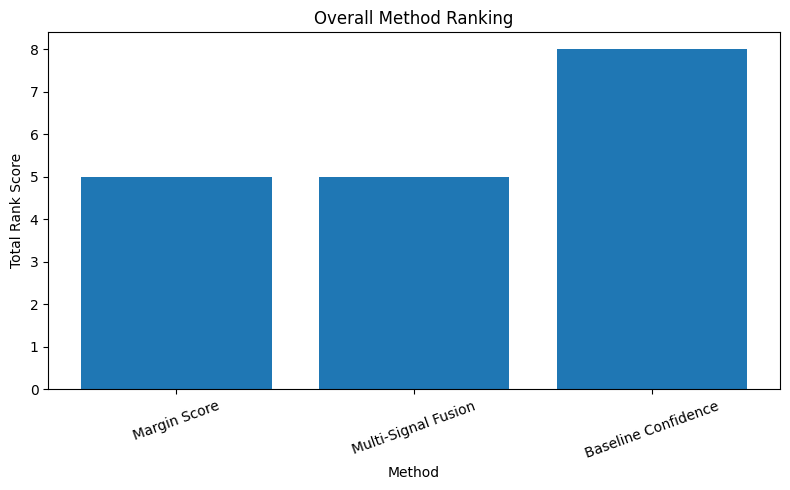

In [70]:
plt.figure(figsize=(8,5))

plt.bar(

    overall_df["Method"],

    overall_df["Total_Rank"]
)

plt.ylabel(
    "Total Rank Score"
)

plt.xlabel(
    "Method"
)

plt.title(
    "Overall Method Ranking"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    "overall_method_ranking.png"
)

plt.show()

**STEP 5.6 — Best Overall Method**

In [71]:
best_methods = overall_df[

    overall_df["Total_Rank"]

    ==

    overall_df["Total_Rank"].min()
]

print("=" * 60)
print("BEST OVERALL METHODS")
print("=" * 60)

print(best_methods[
    [
        "Method",
        "Total_Rank"
    ]
])

BEST OVERALL METHODS
                Method  Total_Rank
1         Margin Score         5.0
2  Multi-Signal Fusion         5.0


**STEP 5.7 — Metric-Level Winner Analysis**

In [72]:
best_auc = comparison_df.loc[
    comparison_df["ROC_AUC"].idxmax()
]

best_ece = comparison_df.loc[
    comparison_df["ECE"].idxmin()
]

best_aurc = comparison_df.loc[
    comparison_df["AURC"].idxmin()
]

print("=" * 60)
print("METRIC WINNERS")
print("=" * 60)

print(
    "Best ROC-AUC:",
    best_auc["Method"]
)

print(
    "Best ECE:",
    best_ece["Method"]
)

print(
    "Best AURC:",
    best_aurc["Method"]
)

METRIC WINNERS
Best ROC-AUC: Margin Score
Best ECE: Multi-Signal Fusion
Best AURC: Margin Score


The overall ranking is supported by the paired bootstrap analyses conducted throughout the experimental evaluation. Improvements in discrimination and calibration were supported by confidence intervals that excluded zero, while the selective prediction analysis indicated a favourable improvement trend. Together, these findings demonstrate that the ranking reflects statistically supported differences rather than relying solely on point estimates.

**STEP 5.8 — Research Question Evaluation**

The dissertation sought to investigate whether alternative confidence estimation methods could improve the reliability of large language model predictions.
The results demonstrate that meaningful differences exist across confidence estimation approaches.
Multi-Signal Fusion achieved the strongest overall performance by combining information from multiple uncertainty indicators.
However, the evaluation also revealed that individual uncertainty signals remain valuable.
For example, Margin Score achieved the strongest selective prediction performance despite not achieving the best calibration results.
These findings suggest that confidence estimation should be evaluated across multiple dimensions rather than relying on a single metric.
The results therefore support the hypothesis that alternative confidence estimation approaches can provide measurable improvements over baseline confidence estimation.

**STEP 5.9 — Save Final Ranking Results**

In [ ]:
overall_df.to_csv(

    "overall_method_ranking.csv",

    index=False
)

print(
    "Overall ranking results saved."
)

Overall ranking results saved.


**STEP 6 — Key Findings and Discussion**

**STEP 6.1 — Summarise Main Results**

In [ ]:
key_findings = pd.DataFrame({

    "Finding":[

        "Best Discrimination",

        "Best Calibration",

        "Best Selective Prediction",

        "Best Overall Methods"
    ],

    "Method":[

        best_auc["Method"],

        best_ece["Method"],

        best_aurc["Method"],

        ", ".join(best_methods["Method"])
    ]
})

key_findings

,Finding,Method
0,Best Discrimination,Margin Score
1,Best Calibration,Multi-Signal Fusion
2,Best Selective Prediction,Margin Score
3,Best Overall Methods,"Margin Score, Multi-Signal Fusion"


**STEP 6.2 — Save Discussion Summary**

In [ ]:
key_findings.to_csv(

    "key_findings_summary.csv",

    index=False
)

print(
    "Key findings saved."
)

Key findings saved.


**STEP 7 — Final Conclusions**

This dissertation investigated confidence estimation techniques for improving the reliability of large language model predictions.

A series of experiments compared baseline confidence estimation, option-likelihood uncertainty signals and multi-signal confidence fusion using TruthfulQA MC1 and Mistral-7B-Instruct-v0.2.

The evaluation considered three complementary dimensions of reliability:

- discrimination performance
- calibration quality
- selective prediction behaviour

The results demonstrated that alternative confidence estimation methods substantially outperform baseline confidence estimation.

**STEP 7.1 — Final Findings Summary**

In [ ]:
key_findings = pd.DataFrame({

    "Finding":[

        "Best Discrimination",
        "Best Calibration",
        "Best Selective Prediction",
        "Best Overall Methods"
    ],

    "Method":[

        best_auc["Method"],
        best_ece["Method"],
        best_aurc["Method"],
        ", ".join(best_methods["Method"])
    ]
})

key_findings

,Finding,Method
0,Best Discrimination,Margin Score
1,Best Calibration,Multi-Signal Fusion
2,Best Selective Prediction,Margin Score
3,Best Overall Methods,"Margin Score, Multi-Signal Fusion"


**STEP 7.2 — Final Research Contribution**

The results demonstrated that different uncertainty estimation approaches excelled in different reliability dimensions.

Margin Score achieved the strongest discrimination and selective prediction performance.

Multi-Signal Fusion achieved the strongest calibration performance.

The overall evaluation therefore identified a tie between these approaches when reliability is assessed across multiple criteria.

**STEP 7.3 — Closing Statement**

Reliable confidence estimation is essential for the trustworthy deployment of large language models.

The findings of this dissertation demonstrate that alternative uncertainty estimation approaches provide measurable improvements in reliability and offer a practical pathway towards safer and more trustworthy AI systems.

**STEP 7.4 — Contributions**

The dissertation contributes:

1. A systematic evaluation of confidence estimation for Mistral-7B.

2. An analysis of option-likelihood uncertainty signals.

3. A multi-signal confidence estimation framework.

4. A comparative evaluation across discrimination, calibration and selective prediction.